# 5. Face Detection: Haar Features, Integral Images and SVMs

Practice for the face detection module: the integral image (any rectangle sum from 4 values), Haar-like
features, a linear SVM trained from scratch on synthetic "face" and "non-face" patches, sliding-window
detection at several scales, and how a non-linear embedding makes a ring-shaped dataset linearly separable.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

np.set_printoptions(precision=3, suppress=True)
plt.rcParams["figure.dpi"] = 80
rng = np.random.default_rng(0)

## 5.1 Integral image

`I(x, y)` = sum of all pixels above and to the left. A rectangle sum is then
`I(D) − I(B) − I(C) + I(A)`: three additions/subtractions on four corner values, whatever the size.

In [2]:
def integral(u):
    return np.pad(u, ((1, 0), (1, 0))).cumsum(0).cumsum(1)

def rect_sum(I, y, x, h, w):
    return I[y + h, x + w] - I[y, x + w] - I[y + h, x] + I[y, x]

u = rng.random((50, 70)); I = integral(u)
checks = [(rect_sum(I, y, x, h, w), u[y:y + h, x:x + w].sum()) for y, x, h, w in [(3, 4, 10, 20), (0, 0, 50, 70), (20, 33, 1, 1)]]
print("integral image rectangle sums correct:", all(np.isclose(a, b) for a, b in checks))

integral image rectangle sums correct: True


## 5.2 Synthetic faces and Haar features

24×24 patches. A "face" is a bright oval with darker eye band, eyes, nose shadow and mouth, under random
brightness, contrast, size jitter and noise. Non-faces are random textures, gradients and blobs. Haar features
are differences of sums over adjacent rectangles (two-, three- and four-rectangle types) at many positions
and sizes; each one costs a handful of integral-image lookups.

1193 Haar features per 24x24 patch; 400 faces, 1600 non-faces (non-faces outnumber faces)


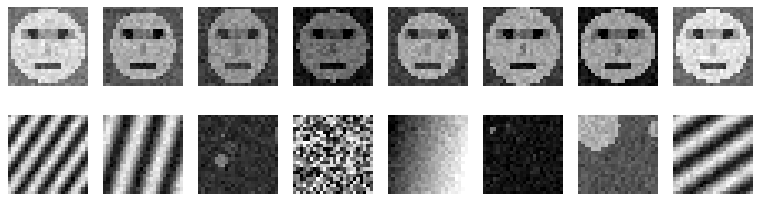

In [3]:
S = 24
def face(r):
    yy, xx = (np.mgrid[:S, :S] - (S - 1) / 2) / (S / 2)
    sx, sy = r.uniform(0.75, 0.95), r.uniform(0.85, 1.0)
    f = np.where((xx / sx) ** 2 + (yy / sy) ** 2 < 1, 0.75, r.uniform(0.1, 0.5))
    f[(np.abs(yy + 0.3) < 0.12) & (np.abs(xx) < 0.7 * sx)] -= 0.25            # eye band
    for ex in (-0.35, 0.35):
        f[(xx - ex) ** 2 + (yy + 0.3) ** 2 < 0.02] = 0.1                       # eyes
    f[(np.abs(xx) < 0.06) & (yy > -0.1) & (yy < 0.25)] -= 0.15                 # nose
    f[(np.abs(yy - 0.5) < 0.06) & (np.abs(xx) < 0.3)] = 0.2                    # mouth
    f = r.uniform(0.6, 1.4) * f + r.uniform(-0.15, 0.15)
    return f + r.normal(0, 0.05, f.shape)

def nonface(r):
    kind = r.integers(4); yy, xx = np.mgrid[:S, :S] / S
    if kind == 0: f = r.random((S, S))
    elif kind == 1: f = r.uniform(0, 1) * xx + r.uniform(0, 1) * yy
    elif kind == 2: f = 0.5 + 0.4 * np.sin(2 * np.pi * (r.uniform(1, 4) * xx + r.uniform(0, 3) * yy))
    else:
        f = np.full((S, S), r.uniform(0, 0.5))
        for _ in range(r.integers(1, 5)):
            cx, cy, rr = r.uniform(0, 1, 3)
            f[(xx - cx) ** 2 + (yy - cy) ** 2 < (0.3 * rr) ** 2] = r.uniform(0, 1)
    return f + r.normal(0, 0.05, f.shape)

def haar_bank():
    feats = []
    for h in (4, 6, 8, 12):
        for w in (4, 6, 8, 12):
            for y in range(0, S - 2 * h + 1, 2):
                for x in range(0, S - 2 * w + 1, 2):
                    feats.append(("v2", y, x, h, w))          # top vs bottom
                    feats.append(("h2", y, x, h, w))          # left vs right
            for y in range(0, S - 3 * h + 1, 3):
                for x in range(0, S - w + 1, 3):
                    feats.append(("v3", y, x, h, w))          # middle band vs top + bottom (eye band)
    return feats

def haar(I, f, oy=0, ox=0, scale=1.0):
    kind, y, x, h, w = f
    y, x, h, w = oy + int(y * scale), ox + int(x * scale), max(1, int(h * scale)), max(1, int(w * scale))
    if kind == "v2": return rect_sum(I, y, x, h, w) - rect_sum(I, y + h, x, h, w)
    if kind == "h2": return rect_sum(I, y, x, h, w) - rect_sum(I, y, x + w, h, w)
    return rect_sum(I, y, x, h, w) + rect_sum(I, y + 2 * h, x, h, w) - 2 * rect_sum(I, y + h, x, h, w)

bank = haar_bank()
def features(patch):
    I = integral((patch - patch.mean()) / (patch.std() + 1e-6))      # variance normalization against lighting
    return np.array([haar(I, f) for f in bank]) / S

Xf = np.array([features(face(rng)) for _ in range(400)]); Xn = np.array([features(nonface(rng)) for _ in range(1600)])
X = np.vstack([Xf, Xn]); y = np.r_[np.ones(400), -np.ones(1600)]
print(f"{len(bank)} Haar features per 24x24 patch; 400 faces, 1600 non-faces (non-faces outnumber faces)")

fig, axes = plt.subplots(2, 8, figsize=(12, 3.2))
for j in range(8):
    axes[0, j].imshow(face(rng), cmap="gray", vmin=0, vmax=1); axes[1, j].imshow(nonface(rng), cmap="gray", vmin=0, vmax=1)
for a in axes.ravel(): a.axis("off")
plt.show()

## 5.3 Linear SVM

`wᵀf + b` with `n + 1` parameters for n features. The SVM minimizes `λ/2 ‖w‖² + mean(max(0, 1 − y(wᵀf + b)))`,
which maximizes the margin; here by sub-gradient descent. Faces are weighted up because they are rare.

In [4]:
mu, sd = X.mean(0), X.std(0) + 1e-9
Xs = (X - mu) / sd
idx = rng.permutation(len(y)); tr, te = idx[:1500], idx[1500:]
w = np.zeros(X.shape[1]); b = 0.0; lam = 1e-3
cw = np.where(y == 1, 4.0, 1.0)
for ep in range(200):
    m = y[tr] * (Xs[tr] @ w + b)
    act = (m < 1) * cw[tr]
    w -= 0.05 * (lam * w - (act * y[tr]) @ Xs[tr] / len(tr))
    b -= 0.05 * (-(act * y[tr]).mean())
score = Xs[te] @ w + b
tp = ((score > 0) & (y[te] == 1)).sum(); fp = ((score > 0) & (y[te] == -1)).sum(); fn = ((score <= 0) & (y[te] == 1)).sum()
print(f"parameters: {len(w)} weights + 1 bias")
print(f"held-out: accuracy {((score > 0) == (y[te] == 1)).mean():.3f}, face recall {tp / (tp + fn):.3f}, false positives {fp} of {(y[te] == -1).sum()}")
print("support vectors (margin ≤ 1 on train):", int((y[tr] * (Xs[tr] @ w + b) <= 1 + 1e-9).sum()))

parameters: 1193 weights + 1 bias
held-out: accuracy 0.994, face recall 1.000, false positives 3 of 392
support vectors (margin ≤ 1 on train): 11


## 5.4 Sliding-window detection at several scales

Slide over a scene with three faces of different sizes. Instead of resizing the image, scale the Haar
rectangles (cheap thanks to the integral image). Every window with `wᵀf + b > 0` is a candidate; real faces
score far higher than background windows, so a detection threshold of 5 trades a little recall for far fewer
false positives. Then non-maximum suppression.

317 windows with score > 0
68 windows with score > 5 -> 3 after NMS; true faces at (x, y, size): [(15, 10, 24), (80, 45, 36), (150, 20, 30)]
detections (x, y, size, score): [(80, 44, 36, 21.98), (14, 10, 24, 20.4), (150, 20, 30, 14.67)]


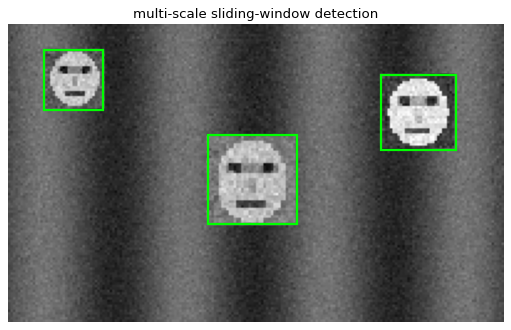

In [5]:
scene = 0.3 + 0.15 * np.sin(np.mgrid[:120, :200][1] / 9.0)
truth = []
for (y0, x0, size) in [(10, 15, 24), (45, 80, 36), (20, 150, 30)]:
    r2 = np.random.default_rng(size)
    f = face(r2); idxs = (np.arange(size) * S / size).astype(int)
    scene[y0:y0 + size, x0:x0 + size] = f[np.ix_(idxs, idxs)]; truth.append((x0, y0, size))
scene += rng.normal(0, 0.03, scene.shape)

dets = []
for size in (24, 30, 36):
    sc = size / S
    for y0 in range(0, 120 - size + 1, 2):
        for x0 in range(0, 200 - size + 1, 2):
            p = scene[y0:y0 + size, x0:x0 + size]
            Ip = integral((p - p.mean()) / (p.std() + 1e-6))
            fv = np.array([haar(Ip, f, 0, 0, sc) for f in bank]) / (S * sc * sc)
            s = ((fv - mu) / sd) @ w + b
            if s > 0: dets.append((float(s), x0, y0, size))
print(f"{len(dets)} windows with score > 0")
dets = sorted([d for d in dets if d[0] > 5], reverse=True); keep = []
for s, x0, y0, size in dets:
    if all(max(0, min(x0 + size, x1 + s1) - max(x0, x1)) * max(0, min(y0 + size, y1 + s1) - max(y0, y1)) < 0.3 * size * size for _, x1, y1, s1 in keep):
        keep.append((s, x0, y0, size))
print(f"{len(dets)} windows with score > 5 -> {len(keep)} after NMS; true faces at (x, y, size): {truth}")
print("detections (x, y, size, score):", [(x, y, s, round(sc_, 2)) for sc_, x, y, s in keep])
plt.figure(figsize=(8, 5)); plt.imshow(scene, cmap="gray", vmin=0, vmax=1)
for _, x0, y0, size in keep:
    plt.gca().add_patch(plt.Rectangle((x0, y0), size, size, fill=False, color="lime", lw=2))
plt.axis("off"); plt.title("multi-scale sliding-window detection"); plt.show()

## 5.5 Non-linearly separable data

Faces in the middle, non-faces in a ring around them: no line separates them in `(x, y)`, but after the
embedding `(x², y²)` they are split by a straight line.

linear SVM accuracy: in (x, y) 0.673, in (x², y²) 1.000


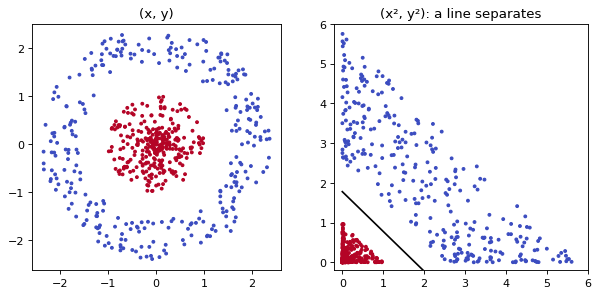

In [6]:
n = 300
r_in, r_out = rng.uniform(0, 1, n), rng.uniform(1.6, 2.4, n)
a1, a2 = rng.uniform(0, 2 * np.pi, n), rng.uniform(0, 2 * np.pi, n)
P = np.r_[np.c_[r_in * np.cos(a1), r_in * np.sin(a1)], np.c_[r_out * np.cos(a2), r_out * np.sin(a2)]]
lab = np.r_[np.ones(n), -np.ones(n)]
E = P ** 2
def train_linear(Z, yv, steps=2000):
    wv, bv = np.zeros(2), 0.0
    for _ in range(steps):
        act = yv * (Z @ wv + bv) < 1
        wv -= 0.05 * (1e-3 * wv - (act * yv) @ Z / len(yv)); bv += 0.05 * (act * yv).mean()
    return ((Z @ wv + bv > 0) == (yv > 0)).mean(), wv, bv
acc_xy, *_ = train_linear(P, lab); acc_e, we, be = train_linear(E, lab)
print(f"linear SVM accuracy: in (x, y) {acc_xy:.3f}, in (x², y²) {acc_e:.3f}")
fig, axes = plt.subplots(1, 2, figsize=(9, 4))
axes[0].scatter(*P.T, c=lab, cmap="coolwarm", s=6); axes[0].set_title("(x, y)"); axes[0].set_aspect("equal")
axes[1].scatter(*E.T, c=lab, cmap="coolwarm", s=6); axes[1].set_title("(x², y²): a line separates")
t = np.linspace(0, 6, 2); axes[1].plot(t, -(we[0] * t + be) / we[1], "k"); axes[1].set_xlim(-0.2, 6); axes[1].set_ylim(-0.2, 6)
plt.show()